# 06 – Mô hình học sâu (PyTorch)

| Mô hình | Bài toán | Ý tưởng |
|---|---|---|
| **NeuMF (NCF)** | Top-N (implicit) | GMF + MLP trên embedding, BCE + lấy mẫu âm (4 âm / 1 dương), dương = rating ≥ 4 |
| **BPR-MF** | Top-N (implicit) | tối ưu thứ hạng cặp (phim thích > phim ngẫu nhiên), dương = rating ≥ 4 |

Siêu tham số (số nhân tố của NeuMF và BPR-MF) được chọn trên tập validation theo tiêu chí **NDCG@10**.

---
### Bản chất từng mô hình

Cả hai mô hình đều huấn luyện bằng gradient (Adam) trên PyTorch và tự dùng GPU. Điểm chung cốt lõi là **mục tiêu tối ưu**: cả hai tối ưu trực tiếp khả năng **xếp hạng** từ dữ liệu implicit (phim user thích so với phim ngẫu nhiên), không tối ưu sai số rating như BiasedMF hay ItemKNN.

**NeuMF (Neural Collaborative Filtering, He et al. 2017):** thay tích vô hướng bằng mạng nơ-ron.
- Bài toán **phân loại nhị phân**: "user $u$ có thích phim $i$ không?".
  - Dương: rating ≥ 4.
  - Âm: mỗi mẫu dương đi kèm 4 phim lấy ngẫu nhiên từ toàn kho, lấy lại mỗi epoch.
- Hai nhánh, mỗi nhánh có bảng embedding riêng:
  - **GMF:** $p_u \odot q_i$, tích từng phần tử. Đây là MF tổng quát hóa: nếu lớp ra là tổng có trọng số bằng 1 thì GMF trở về đúng $p_u^\top q_i$.
  - **MLP:** $[p'_u ; q'_i]$ qua các lớp 64 → 32 → 16 với ReLU, học được tương tác **phi tuyến** mà tích vô hướng không biểu diễn được.
  - Ghép hai nhánh và đi qua một lớp tuyến tính để ra logit; loss là BCE.
- Điểm là logit, chỉ dùng để xếp hạng, không phải số sao.
- Mạnh nhất về NDCG@10. Nhưng mẫu âm lấy đều trên toàn kho nên phần lớn là phim ít người xem, trong khi mẫu dương nghiêng về phim nổi tiếng. Mô hình vì thế dễ học luôn tín hiệu "phim phổ biến thì dễ là dương", và gợi ý thiên về phim nổi tiếng: Novelty thấp, Coverage thấp hơn BPR-MF và ImplicitALS.

**BPR-MF (Bayesian Personalized Ranking, Rendle et al. 2009):** tối ưu **thứ tự** chứ không tối ưu giá trị.
- Mẫu huấn luyện là bộ ba $(u, i, j)$: $i$ là phim user thích (rating ≥ 4), $j$ là phim lấy ngẫu nhiên.
- Mô hình chấm điểm $x_{ui} = p_u^\top q_i + b_i$ và tối đa hóa xác suất user thích $i$ hơn $j$:
$$\max \sum_{(u,i,j)} \ln \sigma(x_{ui} - x_{uj}) - \lambda \|\Theta\|^2$$
- Mô hình không quan tâm $x_{ui}$ bằng bao nhiêu, chỉ cần $x_{ui} > x_{uj}$. Đây đúng là điều một danh sách gợi ý cần, và là xấp xỉ khả vi của AUC.
- Cùng kiến trúc MF với BiasedMF, chỉ khác hàm mục tiêu, nhưng NDCG@10 cao gấp khoảng 5 lần (kể cả khi BiasedMF đã được dò theo NDCG). Điều này cho thấy **hàm mục tiêu quan trọng hơn kiến trúc**.
- So với NeuMF: kém hơn một chút về NDCG nhưng Coverage cao hơn (≈ 0.49 so với ≈ 0.41), đơn giản hơn, và khi triển khai chỉ cần hai ma trận embedding.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import SELECT_METRIC, load_experiment, make_validation, run_model, save_metrics, validate

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
import torch; print("torch", torch.__version__, "| threads:", torch.get_num_threads())
from src.models.neural import NeuMF, BPRMF
sub, val = make_validation(exp)

def run_sweep(make, grid, label):
    out = []
    for p in grid:
        m = make(**p).fit(sub, exp.user2idx, exp.item2idx, exp.movies)
        out.append(dict(Model=label, **p, **validate(m, val))); print(label, p, round(out[-1][SELECT_METRIC], 4))
    return pd.DataFrame(out).sort_values(SELECT_METRIC, ascending=False)

sw = {
    "NeuMF": run_sweep(lambda n_factors: NeuMF(n_factors=n_factors, epochs=6),
                       [dict(n_factors=f) for f in (16, 32, 64, 128)], "NeuMF"),
    "BPR-MF": run_sweep(lambda n_factors: BPRMF(n_factors=n_factors, epochs=20),
                        [dict(n_factors=f) for f in (32, 64, 128)], "BPR-MF"),
}
best = {k: v.iloc[0] for k, v in sw.items()}
pd.concat(sw.values(), ignore_index=True).round(4)

torch 2.11.0+cu128 | threads: 8


NeuMF {'n_factors': 16} 0.1282


NeuMF {'n_factors': 32} 0.1345


NeuMF {'n_factors': 64} 0.1366


NeuMF {'n_factors': 128} 0.1409


BPR-MF {'n_factors': 32} 0.1311


BPR-MF {'n_factors': 64} 0.1285


BPR-MF {'n_factors': 128} 0.1295


,Model,n_factors,ValNDCG@10
0,NeuMF,128,0.1409
1,NeuMF,64,0.1366
2,NeuMF,32,0.1345
3,NeuMF,16,0.1282
4,BPR-MF,32,0.1311
5,BPR-MF,128,0.1295
6,BPR-MF,64,0.1285


In [3]:
models = [NeuMF(n_factors=int(best["NeuMF"].n_factors), epochs=6),
          BPRMF(n_factors=int(best["BPR-MF"].n_factors), epochs=20)]
rows = []
for m in models:
    rows.append(run_model(m, exp)); print("done", m.name)
res = pd.DataFrame(rows)

done NeuMF(f=128)


done BPR-MF(f=32)


In [4]:
res[['Model', 'Precision@10', 'Recall@10', 'NDCG@10', 'HitRate@10', 'Coverage@20', 'FitTime_s']].round(4)

,Model,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,FitTime_s
0,NeuMF(f=128),0.2477,0.1693,0.2946,0.8135,0.4107,12.3079
1,BPR-MF(f=32),0.2293,0.1527,0.2711,0.7829,0.4903,7.4537


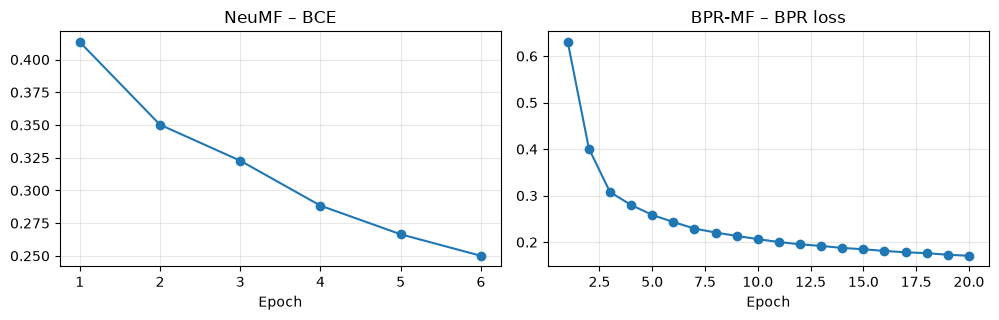

WindowsPath('D:/HỌC/kì 7/Machine Learning/machine_learning/outputs/metrics/deep.csv')

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
for a, m, t in zip(ax, models, ("NeuMF – BCE", "BPR-MF – BPR loss")):
    a.plot(range(1, len(m.history)+1), m.history, marker="o"); a.set(title=t, xlabel="Epoch")
plt.tight_layout(); plt.savefig(FIG / "deep_loss_curves.png"); plt.show()
save_metrics(res.assign(Family="Deep learning"), "deep")